# DialogSum: EDA

Датасет [DialogSum](https://www.kaggle.com/datasets/marawanxmamdouh/dialogsum): бытовые диалоги на английском (`#Person1#`, `#Person2#`) и их краткие саммари. Смотрим, что внутри, длины текстов в словах и токенах, топики и насколько между собой согласны референсы в test.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from rouge_score import rouge_scorer
from transformers import AutoTokenizer

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 200)
ROOT = Path('../..')
CSV = ROOT / 'data/raw/CSV'

## Загрузка и структура

In [2]:
splits = {s: pd.read_csv(CSV / f'{s}.csv') for s in ['train', 'validation', 'test']}
for name, df in splits.items():
    print(f'{name:<11} rows={len(df):>6}  cols={list(df.columns)}  nulls={int(df.isna().sum().sum())}  dup_dialogues={df.dialogue.duplicated().sum()}')

train       rows= 12460  cols=['id', 'dialogue', 'summary', 'topic']  nulls=0  dup_dialogues=2
validation  rows=   500  cols=['id', 'dialogue', 'summary', 'topic']  nulls=0  dup_dialogues=0
test        rows=  1500  cols=['id', 'dialogue', 'summary', 'topic']  nulls=0  dup_dialogues=1000


In [3]:
train, val, test = splits['train'], splits['validation'], splits['test']
print(train.loc[0, 'dialogue'])
print('\nSUMMARY:', train.loc[0, 'summary'])
print('TOPIC:', train.loc[0, 'topic'])

#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some medications that might help. I'll give you more information before you leave.
#Person2#: Ok, thanks doctor.

SUMMARY: Mr. Smith's getting a check-up, and Doctor Hawkins advises

В test у каждого диалога **3 референсных саммари** от разных аннотаторов: id `test_K_1..3`, поэтому 1000 «дубликатов» диалогов. При подсчёте метрик группируем их и считаем multi-reference ROUGE/BLEU.

In [4]:
test['dialogue_id'] = test.id.str.replace(r'_\d+$', '', regex=True)
print('unique test dialogues:', test.dialogue_id.nunique())
test[test.dialogue_id == 'test_0'][['id', 'summary']]

unique test dialogues: 500


,id,summary
0,test_0_1,Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.
1,test_0_2,"In order to prevent employees from wasting time on Instant Message programs, #Person1# decides to terminate the use of those programs and asks Ms. Dawson to send out a memo to all employees by the..."
2,test_0_3,Ms. Dawson takes a dictation for #Person1# about prohibiting the use of Instant Message programs in the office. They argue about its reasonability but #Person1# still insists.


## Длины текстов

In [5]:
for df in splits.values():
    df['dialogue_words'] = df.dialogue.str.split().str.len()
    df['summary_words'] = df.summary.str.split().str.len()
    df['turns'] = df.dialogue.str.count(r'#Person\d+#:')
    df['speakers'] = df.dialogue.apply(lambda x: len(set(re.findall(r'#Person\d+#', x))))
    df['compression'] = df.summary_words / df.dialogue_words
pd.concat({k: v[['dialogue_words', 'summary_words', 'turns', 'speakers', 'compression']].describe(percentiles=[.5, .95, .99]).T for k, v in splits.items()}).round(2)

count    mean    std    min     50%     95%  \
train      dialogue_words  12460.0  130.99  70.98  40.00  116.00  255.00   
           summary_words   12460.0   22.87  10.71   5.00   21.00   42.00   
           turns           12460.0    9.49   4.16   2.00    9.00   16.00   
           speakers        12460.0    2.01   0.13   2.00    2.00    2.00   
           compression     12460.0    0.19   0.05   0.05    0.18    0.27   
validation dialogue_words    500.0  129.34  66.14  40.00  115.00  245.55   
           summary_words     500.0   20.91   9.77   6.00   18.00   39.00   
           turns             500.0    9.38   3.99   2.00    9.00   16.00   
           speakers          500.0    2.01   0.13   2.00    2.00    2.00   
           compression       500.0    0.17   0.05   0.06    0.17    0.25   
test       dialogue_words   1500.0  134.46  75.97  40.00  120.00  253.05   
           summary_words    1500.0   18.75   8.65   4.00   17.00   35.00   
           turns            1500.0    9.71   4.99   2.00    9.00   16.00   
           speakers         1500.0    2.01   0.09   2.00    2.00    2.00   
           compression      1500.0    0.15   0.05   0.04    0.14    0.26   

                              99%     max  
train      dialogue_words  375.00  985.00  
           summary_words    57.00  153.00  
           turns            23.00   61.00  
           speakers          3.00    7.00  
           compression       0.35    0.78  
validation dialogue_words  358.02  472.00  
           summary_words    52.01   65.00  
           turns            20.00   29.00  
           speakers          2.01    4.00  
           compression       0.31    0.51  
test       dialogue_words  358.05  789.00  
           summary_words    48.00   84.00  
           turns            26.00   65.00  
           speakers          2.00    3.00  
           compression       0.34    0.45

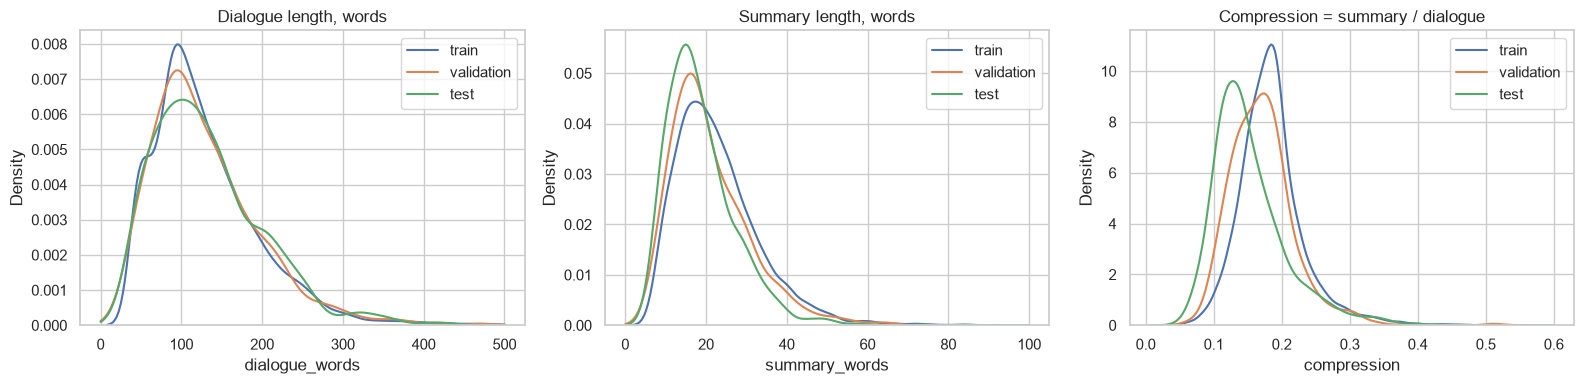

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, df in splits.items():
    sns.kdeplot(df.dialogue_words, ax=axes[0], label=name, clip=(0, 500))
    sns.kdeplot(df.summary_words, ax=axes[1], label=name, clip=(0, 100))
    sns.kdeplot(df.compression, ax=axes[2], label=name, clip=(0, 0.6))
axes[0].set_title('Dialogue length, words'); axes[1].set_title('Summary length, words'); axes[2].set_title('Compression = summary / dialogue')
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

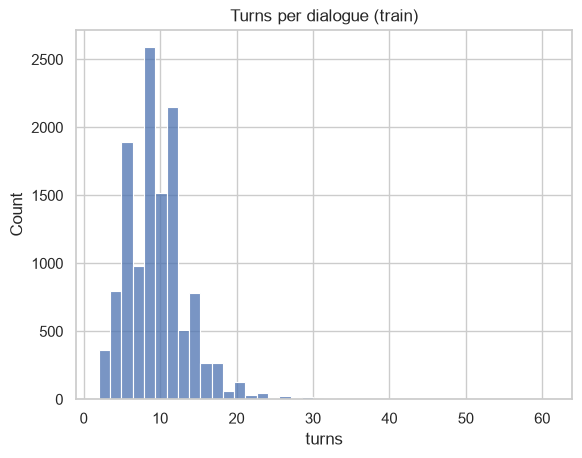

speakers distribution: {2: 12333, 3: 113, 4: 9, 5: 3, 6: 1, 7: 1}


In [7]:
sns.histplot(train.turns, bins=40); plt.title('Turns per dialogue (train)'); plt.show()
print('speakers distribution:', train.speakers.value_counts().to_dict())

## Длины в токенах модели (Qwen2.5-0.5B-Instruct)

Нужны, чтобы выбрать `max_seq_length` для обучения и `max_new_tokens` для генерации.

In [8]:
tok = AutoTokenizer.from_pretrained('Qwen/Qwen2.5-0.5B-Instruct')
sample = train.sample(3000, random_state=42)
dialog_tok = sample.dialogue.apply(lambda x: len(tok(x).input_ids))
summ_tok = sample.summary.apply(lambda x: len(tok(x).input_ids))
pd.DataFrame({'dialogue_tokens': dialog_tok, 'summary_tokens': summ_tok}).describe(percentiles=[.5, .95, .99, .999]).round(0)

,dialogue_tokens,summary_tokens
count,3000.0,3000.0
mean,193.0,35.0
std,96.0,15.0
min,52.0,9.0
50%,176.0,32.0
95%,359.0,61.0
99%,530.0,83.0
99.9%,773.0,113.0
max,990.0,170.0


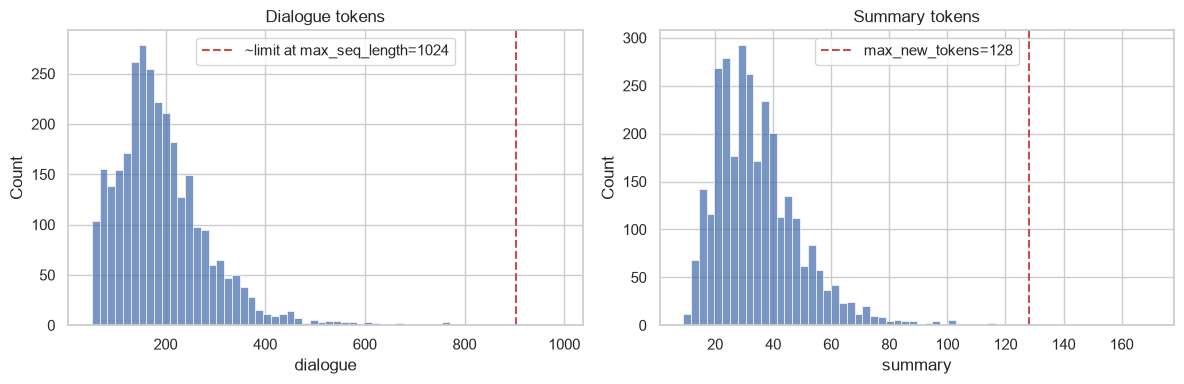

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(dialog_tok, bins=60, ax=axes[0]); axes[0].axvline(1024 - 120, color='r', ls='--', label='~limit at max_seq_length=1024'); axes[0].legend(); axes[0].set_title('Dialogue tokens')
sns.histplot(summ_tok, bins=60, ax=axes[1]); axes[1].axvline(128, color='r', ls='--', label='max_new_tokens=128'); axes[1].legend(); axes[1].set_title('Summary tokens')
plt.tight_layout(); plt.show()

## Топики

unique topics: train 7434 | test 1154


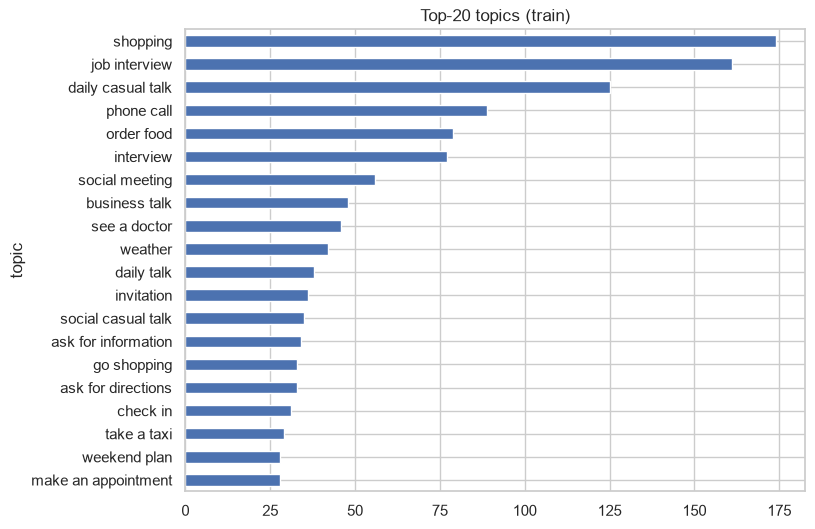

share of test rows whose topic string occurs in train: 0.37


In [10]:
print('unique topics: train', train.topic.nunique(), '| test', test.topic.nunique())
train.topic.value_counts().head(20).plot.barh(figsize=(8, 6)).invert_yaxis(); plt.title('Top-20 topics (train)'); plt.show()
print('share of test rows whose topic string occurs in train:', round(test.topic.isin(set(train.topic)).mean(), 3))

## Стиль саммари

In [11]:
for name, df in splits.items():
    print(f"{name:<11} with #Person tag: {df.summary.str.contains('#Person').mean():.2f}   starts with #Person: {df.summary.str.startswith('#Person').mean():.2f}")
train.summary.str.split().str[:2].str.join(' ').value_counts().head(10)

train       with #Person tag: 0.88   starts with #Person: 0.75
validation  with #Person tag: 0.90   starts with #Person: 0.78
test        with #Person tag: 0.85   starts with #Person: 0.73


summary
#Person1# and        1117
#Person2# tells       933
#Person1# asks        580
#Person1# tells       572
#Person1# wants       442
#Person1# is          318
#Person2# wants       283
#Person2# is          244
#Person1# helps       208
#Person1# invites     204
Name: count, dtype: int64

In [12]:
train.sample(5, random_state=1)[['summary']]

,summary
4316,"#Person1# and #Person2# are moving into their own home and although it is small, they are still happy with it and they are arranging the furniture."
2813,#Person1# spends free time learning German and playing the piano. #Person2# recommends skating but #Person1# gave it up because #Person1# once broke #Person1#'s leg while skating.
3793,#Person2# tells #Person1# the galaxies sit more or less passively in the space and galaxies may collide because the gravity may disturb the motion of a galaxy's neighbor.
3773,#Person2# serves #Person1# to try the dress on.
3058,#Person2# tells #Person1# how to get to the railway station.


## Согласие аннотаторов в test

Считаем ROUGE каждого референса против двух оставшихся (leave-one-out). Это ориентир «человеческого» уровня: модели меряются против трёх референсов, так что у них даже небольшая фора.

In [13]:
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
scores = []
for _, grp in test.groupby('dialogue_id'):
    refs = grp.summary.tolist()
    for i, ref in enumerate(refs):
        s = scorer.score_multi([r for j, r in enumerate(refs) if j != i], ref)
        scores.append({k: v.fmeasure * 100 for k, v in s.items()})
pd.DataFrame(scores).mean().round(2)

rouge1    59.61
rouge2    34.11
rougeL    51.84
dtype: float64

## Выводы по EDA

- **Объём**: 12 460 train, 500 validation, 500 test-диалогов (1 500 строк, по 3 референса). Пропусков нет, в train 2 дубликата диалогов.
- **Короткие диалоги**: в среднем ~130 слов и ~9–10 реплик, 95-й перцентиль около 255 слов. Почти всегда 2 спикера.
- **Сильное сжатие**: саммари ~20 слов, это ~15–18% длины диалога. Задача абстрактивная: нужно 1–2 предложения от третьего лица, а не выдержка из диалога. Поэтому экстрактивный бейзлайн «первое + последнее предложение» должен быть слабым.
- **Специфичный стиль**: ~85–90% саммари упоминают `#Person1#`/`#Person2#`, многие начинаются с `#Person1# ...`. Zero-shot модель этот стиль не знает, поэтому прописываем его в промпте. LoRA должна выучить его лучше всего, и именно на этом стиле можно выиграть в ROUGE.
- **Токены**: диалог в токенах Qwen в среднем ~195, p99 ~540, максимум ~1 360. Саммари p99 ~85 токенов. Берём `max_seq_length=1024`: обрезается меньше 0,1% примеров. `max_new_tokens=128` с запасом, `max_model_len=2048` для vLLM.
- **Топики**: тысячи уникальных строк с длинным хвостом (shopping, job interview, daily casual talk...). Темы бытовые, домен однородный. Для LoRA хватит пары тысяч примеров: берём случайные 2 000 из train и 200 из validation для eval loss.
- **Референсы расходятся**: ROUGE-L референса против двух других около 50, ROUGE-2 около 34. Это практический потолок метрики: человек при пересказе тоже формулирует по-своему. Значит, ROUGE стоит дополнять LLM-as-judge.
